# Titanic - Exploratory Data Analysis

## 1. Introduction

The goal of this project is to predict passenger survival
on the Titanic using machine learning.

This notebook explores the dataset, examines feature 
distributions, identifies missing values, and investigates 
potential relationships between passenger characteristics 
and survival.

## 2. Data Overview

We begin by examining the dataset structure, feature types, 
summary statistics, and class distribution.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

plt.style.use('dark_background')

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 120,
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.2,
})

In [2]:
DATA_DIR = Path('../data')

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')

In [3]:
print('Train shape:', train.shape)
print('Test shape:', test.shape)

Train shape: (891, 12)
Test shape: (418, 11)


In [4]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
train.describe(include="object")

C:\Users\coffe\AppData\Local\Temp\ipykernel_18880\4058271388.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [8]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

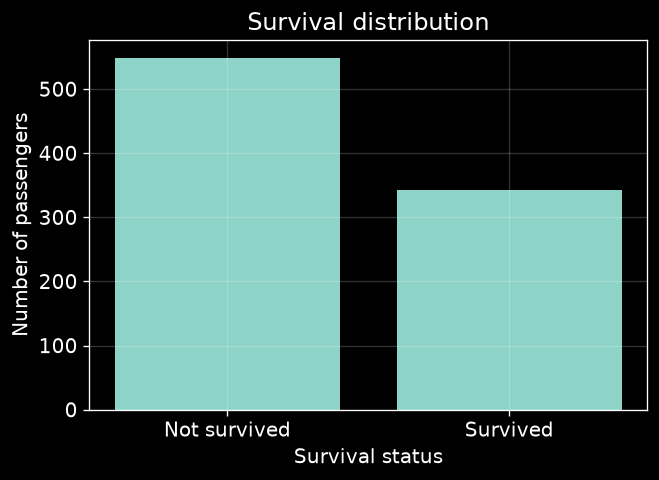

In [9]:
survival_counts = train['Survived'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    ['Not survived', 'Survived'],
    survival_counts.values
)

ax.set_title('Survival distribution')
ax.set_xlabel('Survival status')
ax.set_ylabel('Number of passengers')

plt.show()

In [10]:
train['Survived'].value_counts().sort_index()

Survived
0    549
1    342
Name: count, dtype: int64

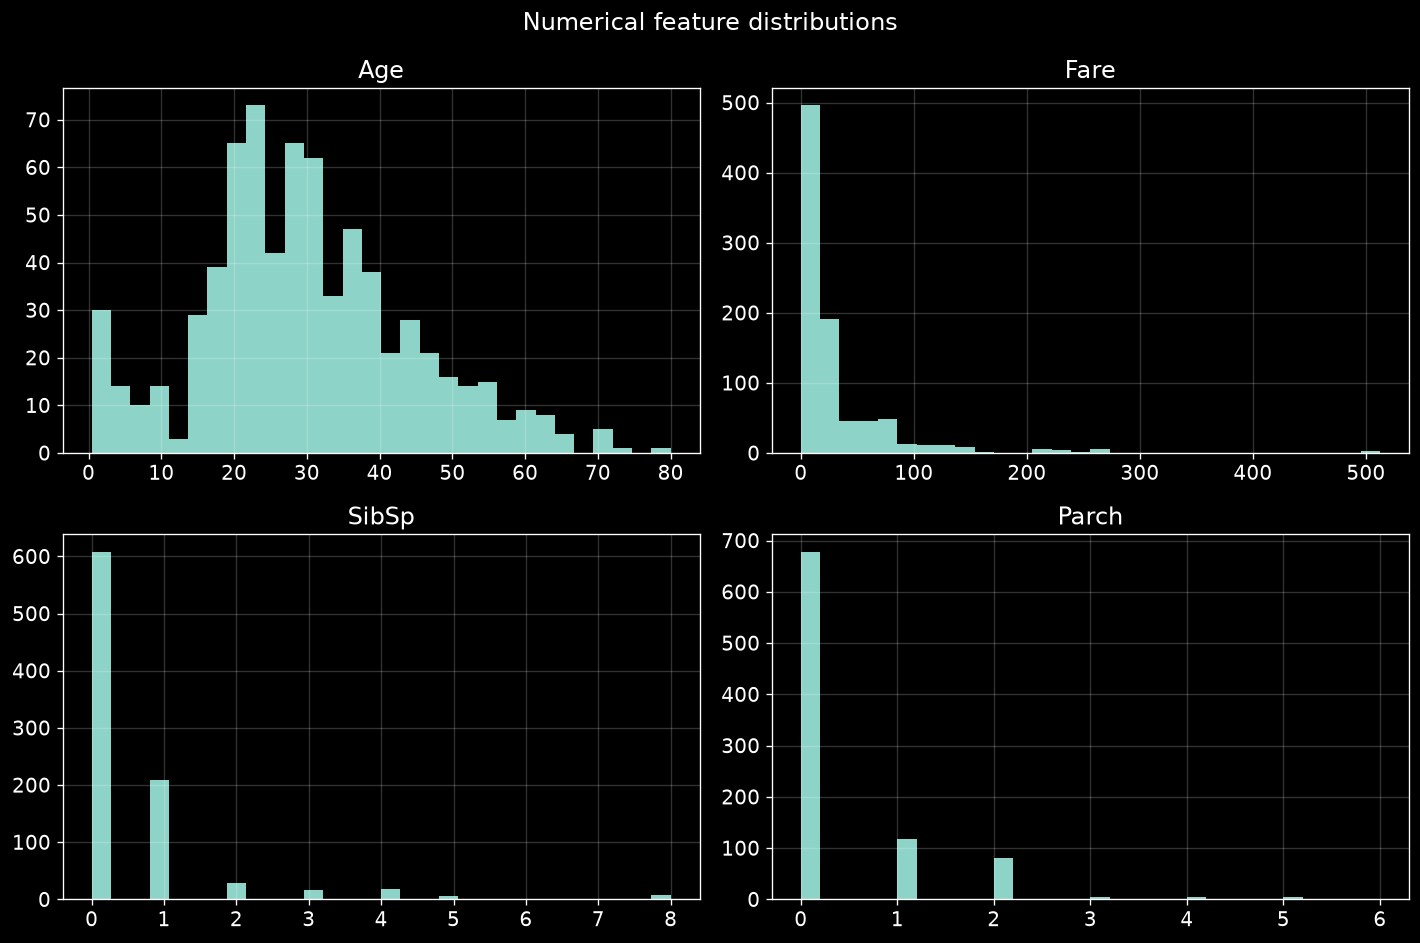

In [11]:
numeric_features = ["Age", "Fare", "SibSp", "Parch"]

train[numeric_features].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Numerical feature distributions")
plt.tight_layout()
plt.show()

### Initial Findings

* The training dataset contains 891 observations and 12 columns, including the target variable `Survived`.
* Approximately 38.4% of passengers survived, indicating a moderate class imbalance.
* Missing values are present in `Age` (19.9%), `Cabin` (77.1%), and `Embarked` (0.2%).
* The `Fare` distribution is strongly right-skewed, with a small number of unusually high values.
* `SibSp` and `Parch` are concentrated around zero, suggesting that many passengers traveled without the corresponding family members.
* Further analysis is needed to determine how passenger characteristics relate to survival.

## 3. Survival Analysis

We investigate how passenger characteristics are associated with survival.

In particular, we examine survival rates across gender and passenger classes to identify potentially informative features.

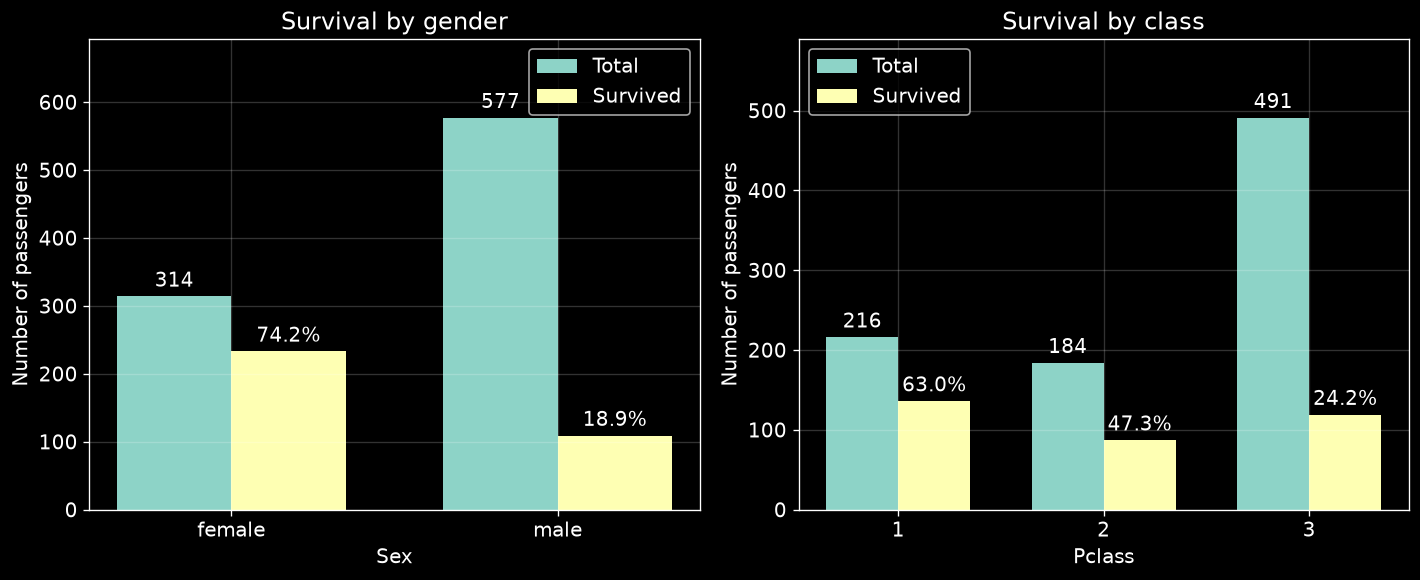

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

features = ["Sex", "Pclass"]
titles = ["Survival by gender", "Survival by class"]

for ax, feature, title in zip(axes, features, titles):

    stats = train.groupby(feature)["Survived"].agg(
        total="count",
        survived="sum"
    )

    stats["survival_rate"] = stats["survived"] / stats["total"]

    x = np.arange(len(stats))
    width = 0.35

    total_bars = ax.bar(
        x - width / 2,
        stats["total"],
        width,
        label="Total"
    )

    survived_bars = ax.bar(
        x + width / 2,
        stats["survived"],
        width,
        label="Survived"
    )

    ax.bar_label(total_bars, padding=3)

    ax.bar_label(
        survived_bars,
        labels=[
            f"{rate:.1%}"
            for rate in stats["survival_rate"]
        ],
        padding=3
    )

    ax.set_title(title)
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of passengers")
    ax.set_xticks(x)
    ax.set_xticklabels(stats.index.astype(str))
    ax.set_ylim(0, stats["total"].max() * 1.2)
    ax.legend()

plt.tight_layout()
plt.show()

### Survival Analysis — Key Findings

**Gender**

Female passengers had a substantially higher survival rate (approximately 74%) than male passengers (19%). This suggests that `Sex` is a potentially important predictor of survival.

**Passenger Class**

Survival rates differed considerably across passenger classes:

* First class: approximately 63%.
* Second class: approximately 47%.
* Third class: approximately 24%.

A clear association between passenger class and survival is observed. However, these results alone do not establish a causal relationship.

Both `Sex` and `Pclass` should be considered in subsequent modeling experiments.

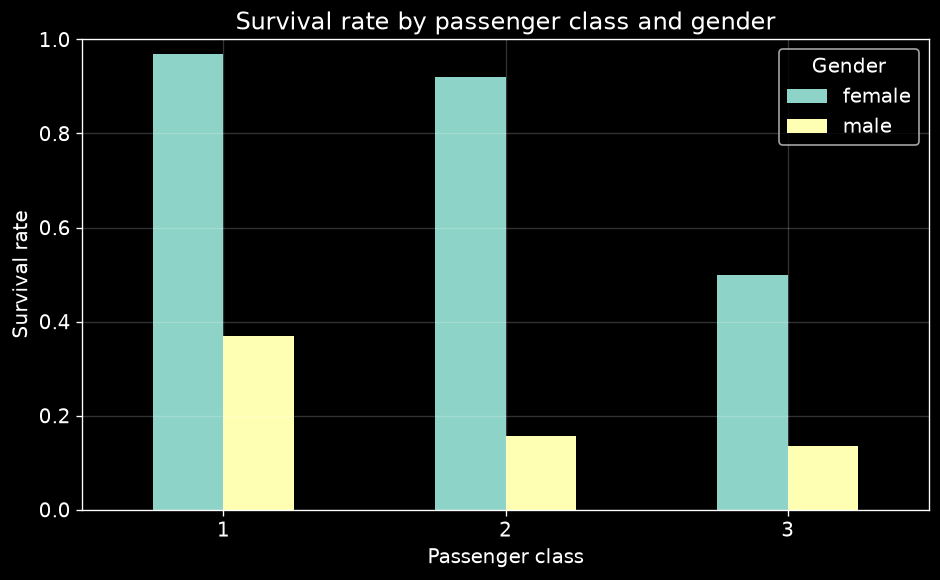

In [13]:
survival_by_group  = (
    train.groupby(['Pclass', 'Sex'])['Survived']
    .mean()
    .unstack()
)

ax = survival_by_group.plot(
    kind='bar',
    figsize=(8, 5),
    rot=0
)

ax.set_title("Survival rate by passenger class and gender")
ax.set_xlabel("Passenger class")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)
ax.legend(title="Gender")

plt.tight_layout()
plt.show()

### Interaction Between Gender and Passenger Class

The analysis reveals a strong association between both gender and passenger class and survival.

Female passengers had higher survival rates than male passengers across all three classes. Women in first and second class had particularly high survival rates, exceeding 90%.

Passenger class was also associated with survival. Among women, the survival rate decreased substantially in third class. Among men, first-class passengers had a higher survival rate than those in second and third class.

Interestingly, third-class women had a higher survival rate (approximately 50%) than first-class men (approximately 37%).

These findings suggest that the relationship between passenger class and survival may differ by gender. Both features, as well as their potential interaction, are worth investigating during feature engineering.

## 4. Age Analysis

We investigate the relationship between passenger age and survival.

The `Age` feature contains 177 missing values (19.9% of the training dataset). Therefore, the following analysis is based on passengers with known ages.

We first compare the age distributions of survivors and non-survivors.

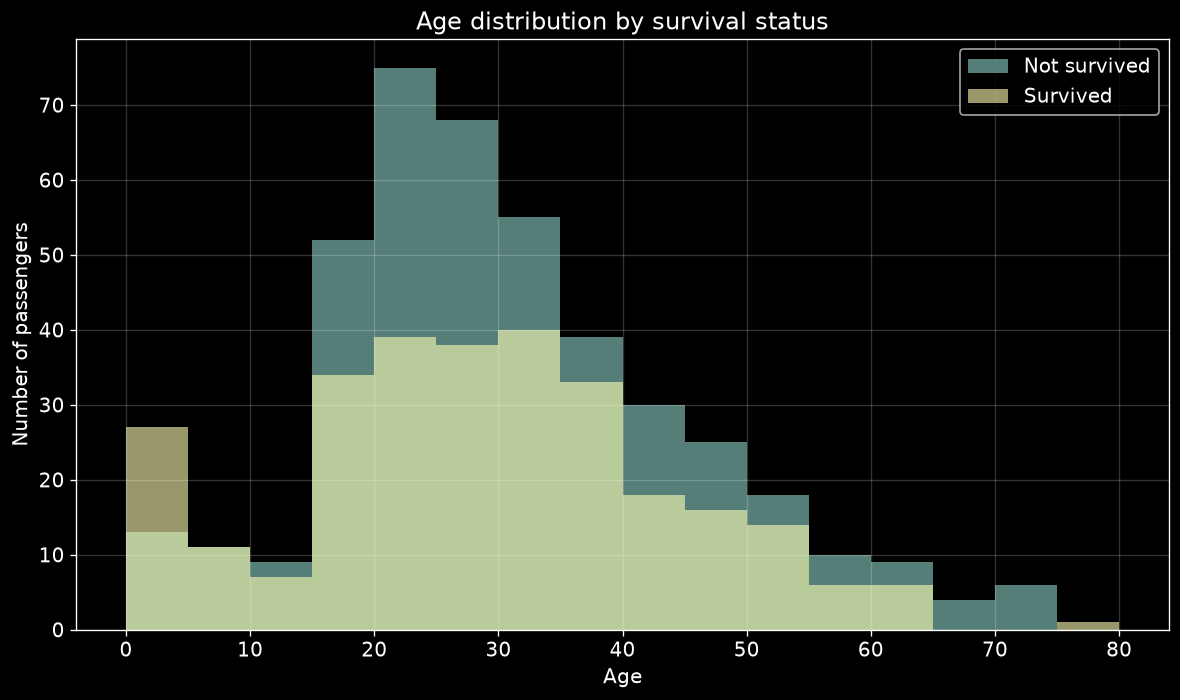

In [14]:
fig, ax = plt.subplots()

for survived, label in [(0, 'Not survived'), (1, 'Survived')]:
    ages = train.loc[train['Survived'] == survived, 'Age'].dropna()
    
    ax.hist(
        ages,
        bins=np.arange(0, 85, 5),
        alpha=0.6,
        label=label
    )
        
ax.set_title('Age distribution by survival status')
ax.set_xlabel('Age')
ax.set_ylabel('Number of passengers')
ax.legend()

plt.tight_layout()
plt.show()

In [15]:
age_bins = [0, 12, 18, 30, 45, 60, np.inf]

age_labels = [
    '0-12',
    '13-18',
    '19-30',
    '31-45',
    '46-60',
    '60+'
]

age_groups = pd.cut(
    train['Age'],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_stats = (
    train.groupby(age_groups, observed=True)['Survived']
    .agg(total='count', survived='sum', survival_rate='mean')
)

age_stats

,total,survived,survival_rate
Age,,,
0-12,69,40,0.579710
13-18,70,30,0.428571
19-30,270,96,0.355556
31-45,202,86,0.425743
46-60,81,33,0.407407
60+,22,5,0.227273


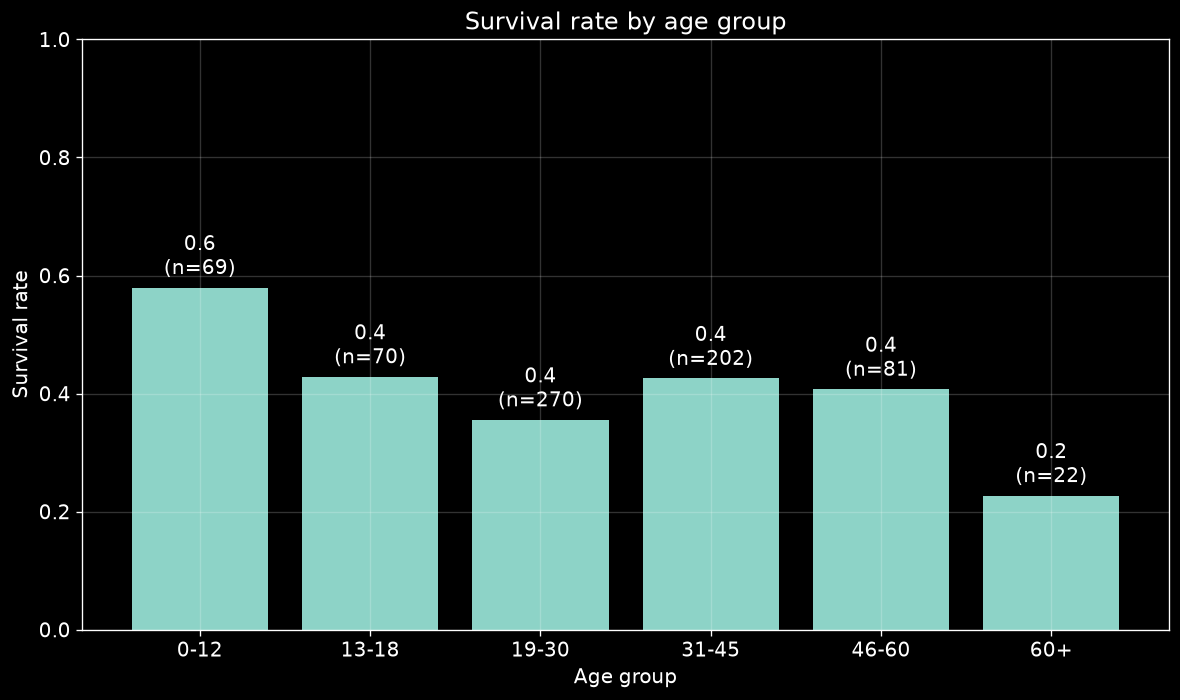

In [16]:
fig, ax = plt.subplots()

bars = ax.bar(
    age_stats.index.astype(str),
    age_stats['survival_rate']
)

ax.bar_label(
    bars,
    labels=[
        f'{rate:.1}\n(n={count})'
        for rate, count in zip(
            age_stats['survival_rate'],
            age_stats['total']
        )
    ],
    padding=4
)

ax.set_title("Survival rate by age group")
ax.set_xlabel("Age group")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

### Age Analysis — Key Findings

The relationship between age and survival is not strictly monotonic.

Children aged 0–12 had the highest observed survival rate (58.0%), while passengers older than 60 had the lowest (22.7%).

Survival rates among passengers aged 13–60 ranged from approximately 36% to 43%, without a consistent increasing or decreasing trend.

The oldest age group contains only 22 passengers, so its estimated survival rate should be interpreted cautiously.

Additionally, 19.9% of passengers have missing age values. The analysis is therefore limited to passengers with known ages.

These findings suggest that age may be a useful predictor, particularly for identifying younger passengers. However, its relationship with survival should also be examined alongside gender and passenger class.


## 5. Family Analysis

We investigate whether traveling with family members is associated with passenger survival.

The dataset provides two family-related features:

* `SibSp`: Number of siblings and spouses aboard.
* `Parch`: Number of parents and children aboard.

We first examine their individual relationships with survival before constructing a combined family-size feature.

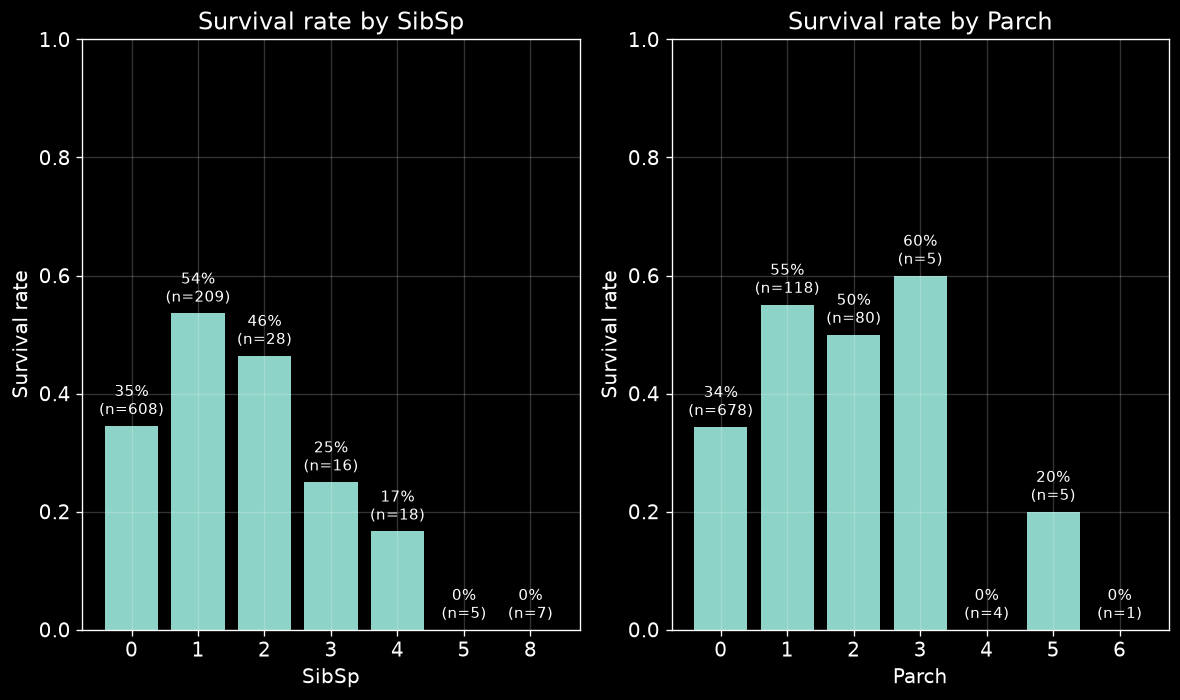

In [17]:
fig, axes = plt.subplots(1, 2)

features = ['SibSp', 'Parch']

for ax, feature in zip(axes, features):
    stats = (
        train.groupby(feature)['Survived']
        .agg(total='count', survived='sum', survival_rate='mean')
    )
    
    bars = ax.bar(
        stats.index.astype(str),
        stats['survival_rate']
    )
    
    ax.bar_label(
        bars,
        labels=[
            f'{rate:.0%}\n(n={count})'
            for rate, count in zip(
                stats['survival_rate'],
                stats['total']
            )
        ],
        padding=4,
        fontsize=9
    )
    
    ax.set_title(f"Survival rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 1)
    
plt.tight_layout()
plt.show()

In [18]:
family_df = train.copy()

family_df['FamilySize'] = (
    family_df['SibSp']
    + family_df['Parch']
    + 1
)

family_stats = (
    family_df.groupby('FamilySize')['Survived']
    .agg(total='count', survived='sum', survival_rate='mean')
)

family_stats

,total,survived,survival_rate
FamilySize,,,
1,537,163,0.303538
2,161,89,0.552795
3,102,59,0.578431
4,29,21,0.724138
5,15,3,0.200000
6,22,3,0.136364
7,12,4,0.333333
8,6,0,0.000000
11,7,0,0.000000


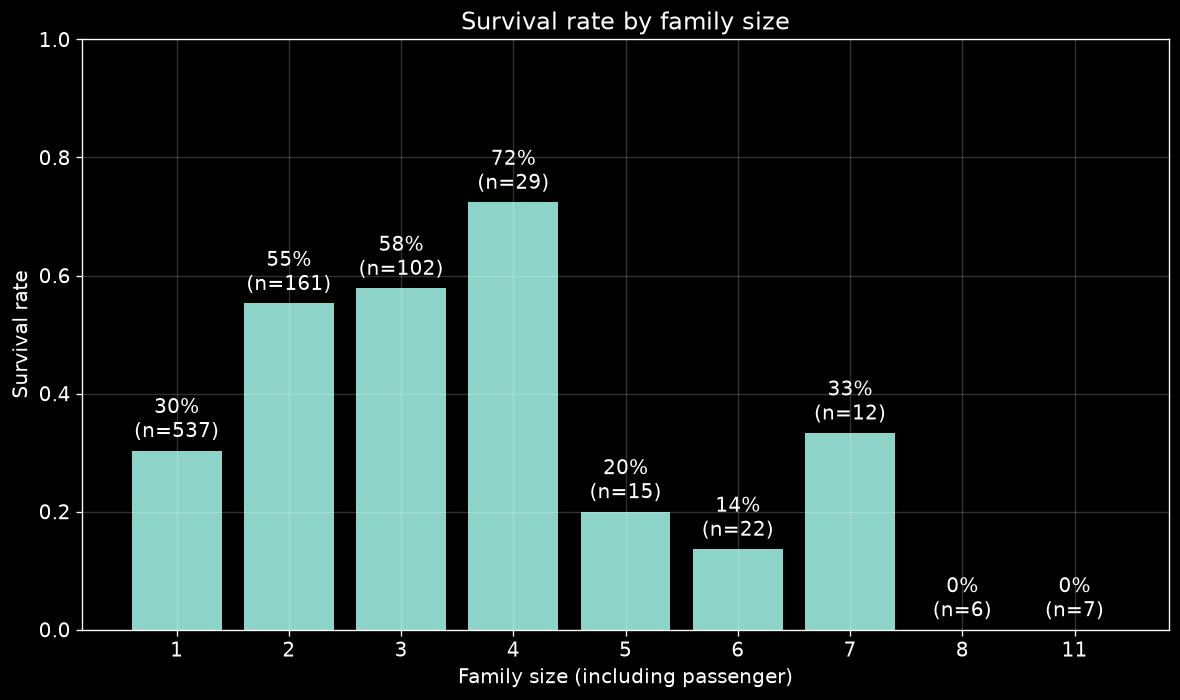

In [19]:
fig, ax = plt.subplots()

bars = ax.bar(
    family_stats.index.astype(str),
    family_stats['survival_rate']
)

ax.bar_label(
    bars,
    labels=[
        f'{rate:.0%}\n(n={count})'
        for rate, count in zip(
            family_stats['survival_rate'],
            family_stats['total']
        )
    ],
    padding=4
)

ax.set_title("Survival rate by family size")
ax.set_xlabel("Family size (including passenger)")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [20]:

family_df["IsChild"] = family_df["Age"] <= 12

family_df["FamilyGroup"] = pd.cut(
    family_df["FamilySize"],
    bins=[0, 1, 4, float("inf")],
    labels=["Alone", "Small family (2–4)", "Large family (5+)"]
)

# Exclude passengers with unknown ages
age_family_df = family_df.dropna(subset=["Age"])

age_family_stats = (
    age_family_df
    .groupby(["FamilyGroup", "IsChild"], observed=True)["Survived"]
    .agg(
        total="count",
        survived="sum",
        survival_rate="mean"
    )
)

age_family_stats

total  survived  survival_rate
FamilyGroup        IsChild                                
Alone              False      402       129       0.320896
                   True         2         1       0.500000
Small family (2–4) False      218       113       0.518349
                   True        41        37       0.902439
Large family (5+)  False       25         8       0.320000
                   True        26         2       0.076923

### Family Analysis — Key Findings

Family-related features show a non-linear association with survival.

Passengers traveling alone had a relatively low survival rate (approximately 30%). Those with a family size of 2–4 had substantially higher survival rates, ranging from 55% to 72%.

Survival rates decreased among passengers with larger family sizes. However, these groups contain relatively few observations, so their results should be interpreted cautiously.

A possible explanation for the higher survival rates among smaller families is the presence of children, who also showed higher survival rates in the age analysis. Further investigation is needed to determine whether this relationship persists when age is taken into account.

The combined `FamilySize` feature and a potential `IsAlone` indicator are promising candidates for future feature engineering.

### Age and Family Size Interaction

The analysis reveals a substantial difference in child survival rates across family-size groups.

Among children aged 12 or younger, 37 out of 41 passengers traveling in small families (2–4 members) survived, corresponding to a survival rate of 90.2%.

In contrast, only 2 out of 26 children traveling in large families (5+ members) survived (7.7%).

Adults traveling in small families also had a higher observed survival rate (51.8%) than those traveling alone (32.1%).

These findings suggest a potential interaction between age and family size. However, passenger class and other characteristics may contribute to the observed differences.

Further analysis could investigate whether the relationship persists within individual passenger classes.

## 6. Fare Analysis

The `Fare` feature represents the passenger fare.

Its distribution is strongly right-skewed, with a median of 14.45 and a maximum value of 512.33.

We investigate the relationship between fare, passenger class, and survival.

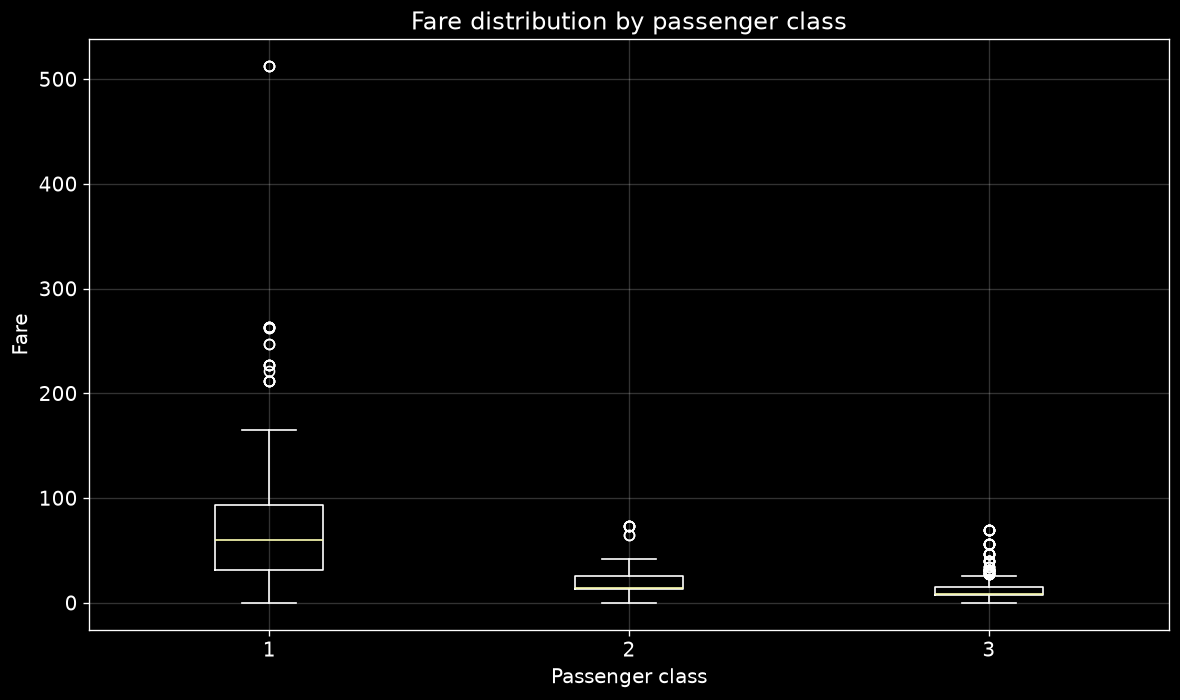

In [23]:
fig, ax = plt.subplots()

fare_by_class = [
    train.loc[train['Pclass'] == pclass, 'Fare']
    for pclass in [1, 2, 3]
]

ax.boxplot(
    fare_by_class,
    tick_labels=[1, 2, 3]
)

ax.set_title("Fare distribution by passenger class")
ax.set_xlabel("Passenger class")
ax.set_ylabel("Fare")

plt.tight_layout()
plt.show()

In [25]:
fare_groups = pd.qcut(
    train['Fare'],
    q=4,
    duplicates='drop'
)

fare_stats = (
    train.groupby(fare_groups, observed=True)['Survived']
    .agg(total='count', survived='sum', survival_rate='mean')
)

fare_stats

,total,survived,survival_rate
Fare,,,
"(-0.001, 7.91]",223,44,0.197309
"(7.91, 14.454]",224,68,0.303571
"(14.454, 31.0]",222,101,0.454955
"(31.0, 512.329]",222,129,0.581081


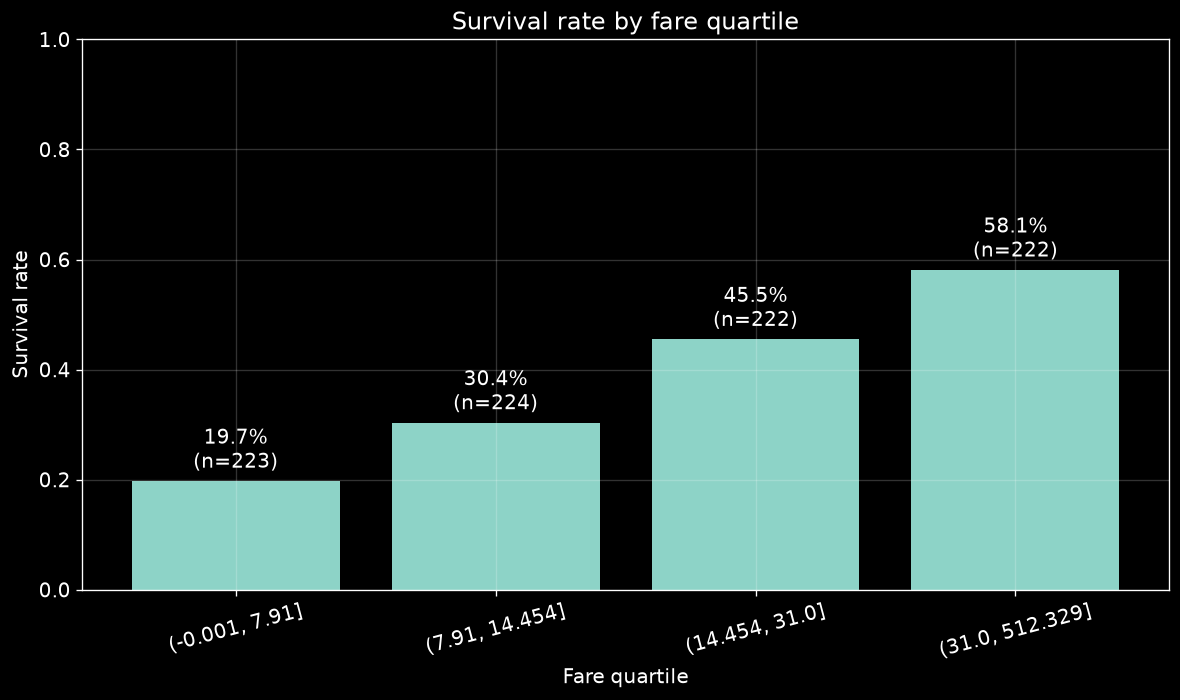

In [26]:
fig, ax = plt.subplots()

bars = ax.bar(
    fare_stats.index.astype(str),
    fare_stats['survival_rate']
)

ax.bar_label(
    bars,
    labels=[
        f'{rate:.1%}\n(n={count})'
        for rate, count in zip(
            fare_stats['survival_rate'],
            fare_stats['total']
        )
    ],
    padding=4
)

ax.set_title("Survival rate by fare quartile")
ax.set_xlabel("Fare quartile")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Fare Analysis — Key Findings

The `Fare` distribution is strongly right-skewed, with several exceptionally high values.

First-class passengers generally paid higher fares than passengers in second and third class.

Survival rates increased across fare quartiles, from 19.7% in the lowest quartile to 58.1% in the highest.

However, fare is associated with passenger class, which may partially explain its relationship with survival. Additionally, some fares may represent shared tickets rather than individual ticket prices.

A logarithmic transformation of `Fare` could be investigated during preprocessing, with its usefulness evaluated through cross-validation.

## 7. Embarked Analysis

The `Embarked` feature indicates the port where a passenger boarded the Titanic.

The three possible values are:

* `C`: Cherbourg, France.
* `Q`: Queenstown, Ireland.
* `S`: Southampton, England.

The feature contains only two missing values in the training dataset.

We investigate the distribution of passengers across embarkation ports and examine the relationship between embarkation port, survival, and passenger class.


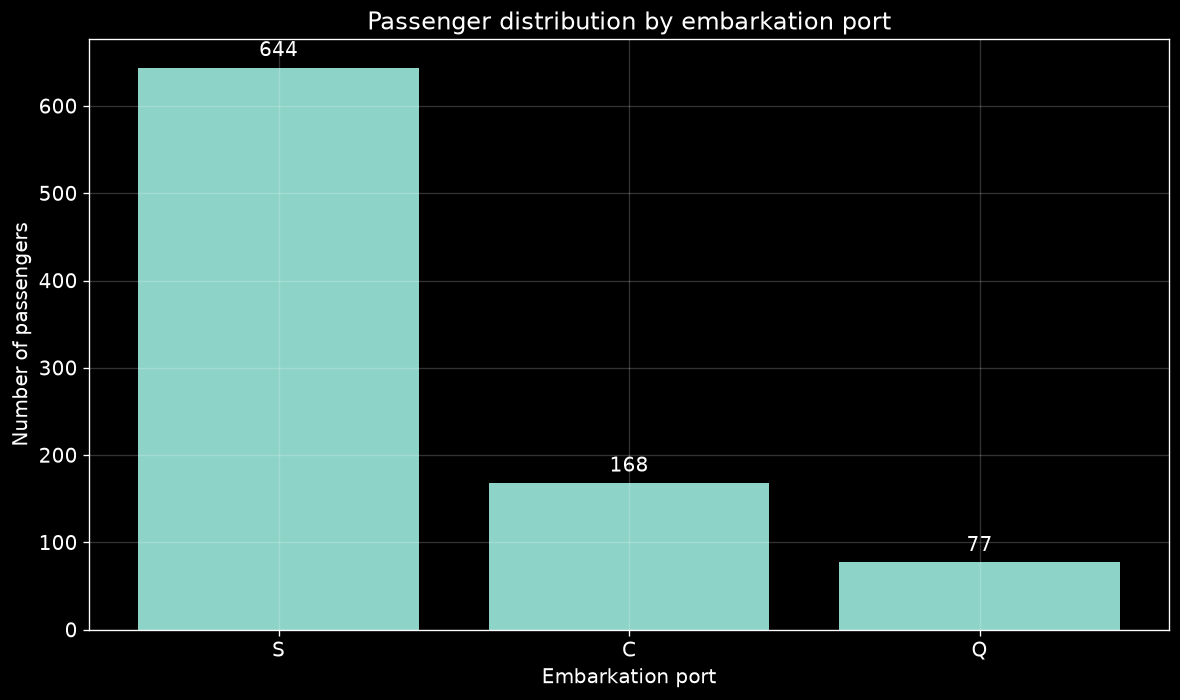

In [30]:
embarked_counts = train['Embarked'].value_counts()

fig, ax = plt.subplots()

bars = ax.bar(
    embarked_counts.index,
    embarked_counts.values
)

ax.bar_label(bars, padding=4)

ax.set_title("Passenger distribution by embarkation port")
ax.set_xlabel("Embarkation port")
ax.set_ylabel("Number of passengers")

plt.tight_layout()
plt.show()

In [31]:
embarked_stats = (
    train.groupby("Embarked")["Survived"]
    .agg(
        total="count",
        survived="sum",
        survival_rate="mean"
    )
)

embarked_stats

,total,survived,survival_rate
Embarked,,,
C,168,93,0.553571
Q,77,30,0.389610
S,644,217,0.336957


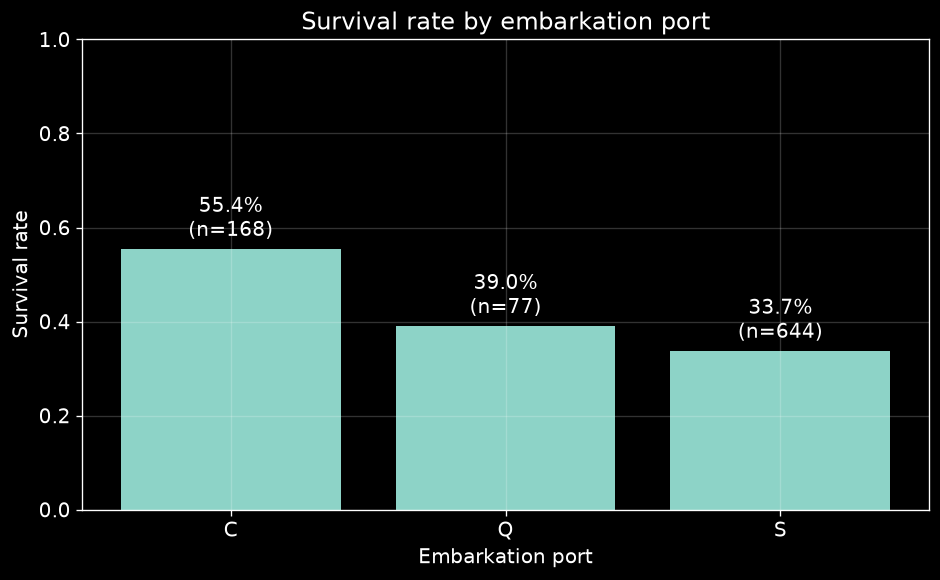

In [32]:

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    embarked_stats.index,
    embarked_stats["survival_rate"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.1%}\n(n={count})"
        for rate, count in zip(
            embarked_stats["survival_rate"],
            embarked_stats["total"]
        )
    ],
    padding=4
)

ax.set_title("Survival rate by embarkation port")
ax.set_xlabel("Embarkation port")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [33]:
port_class = pd.crosstab(
    train["Embarked"],
    train["Pclass"],
    normalize="index"
)

port_class

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137


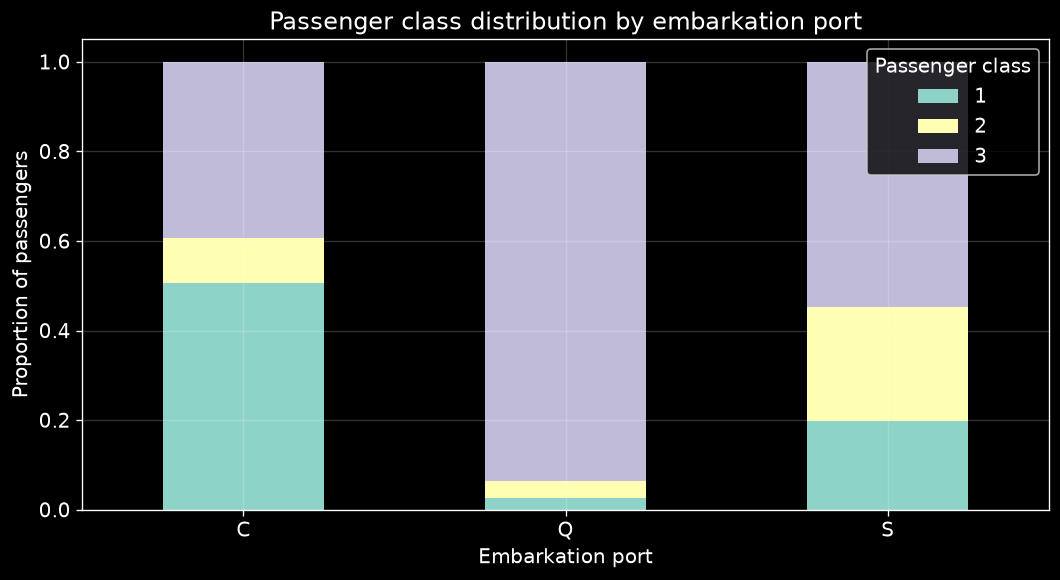

In [34]:

ax = port_class.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    rot=0
)

ax.set_title("Passenger class distribution by embarkation port")
ax.set_xlabel("Embarkation port")
ax.set_ylabel("Proportion of passengers")
ax.legend(title="Passenger class")

plt.tight_layout()
plt.show()

In [35]:

port_class_stats = (
    train.groupby(["Pclass", "Embarked"])["Survived"]
    .agg(
        total="count",
        survived="sum",
        survival_rate="mean"
    )
)

port_class_stats

total  survived  survival_rate
Pclass Embarked                                
1      C            85        59       0.694118
       Q             2         1       0.500000
       S           127        74       0.582677
2      C            17         9       0.529412
       Q             3         2       0.666667
       S           164        76       0.463415
3      C            66        25       0.378788
       Q            72        27       0.375000
       S           353        67       0.189802

### Embarked Analysis — Key Findings

Most passengers embarked in Southampton (644), followed by Cherbourg (168) and Queenstown (77).

Cherbourg had the highest observed survival rate (55.4%), compared with Queenstown (39.0%) and Southampton (33.7%).

The distribution of passenger classes differed substantially across embarkation ports. Approximately half of the passengers embarking in Cherbourg traveled in first class, whereas Queenstown was dominated by third-class passengers.

This suggests that the association between embarkation port and survival may be partially explained by passenger class.

Further analysis within individual passenger classes is needed to investigate whether differences between ports persist after accounting for class.

The `Embarked` feature contains only two missing values, which will be handled during preprocessing.


### Embarked Analysis — Additional Findings

After grouping passengers by both embarkation port and passenger class, differences in survival rates remain visible within individual classes.

In third class, passengers embarking in Cherbourg and Queenstown had survival rates of approximately 38%, compared with 19% among those embarking in Southampton.

This suggests that passenger class alone does not fully explain the observed association between embarkation port and survival.

However, several class-port combinations contain very few passengers, particularly first- and second-class passengers embarking in Queenstown. Their survival rates should therefore be interpreted cautiously.

Other characteristics, such as gender and age, may contribute to the remaining differences.

The predictive value of `Embarked` will be evaluated during model training rather than determined solely from these descriptive statistics.

## 8. Cabin Analysis

The `Cabin` feature contains cabin identifiers, such as `C85` or `E46`.

Approximately 77.1% of its values are missing. Before deciding how to handle these missing values, we investigate whether cabin availability and cabin location are associated with survival.

We first compare survival rates between passengers with known and unknown cabin information.

In [36]:

cabin_df = train.copy()

cabin_df["HasCabin"] = cabin_df["Cabin"].notna().astype(int)

cabin_stats = (
    cabin_df.groupby("HasCabin")["Survived"]
    .agg(
        total="count",
        survived="sum",
        survival_rate="mean"
    )
)

cabin_stats

,total,survived,survival_rate
HasCabin,,,
0,687,206,0.299854
1,204,136,0.666667


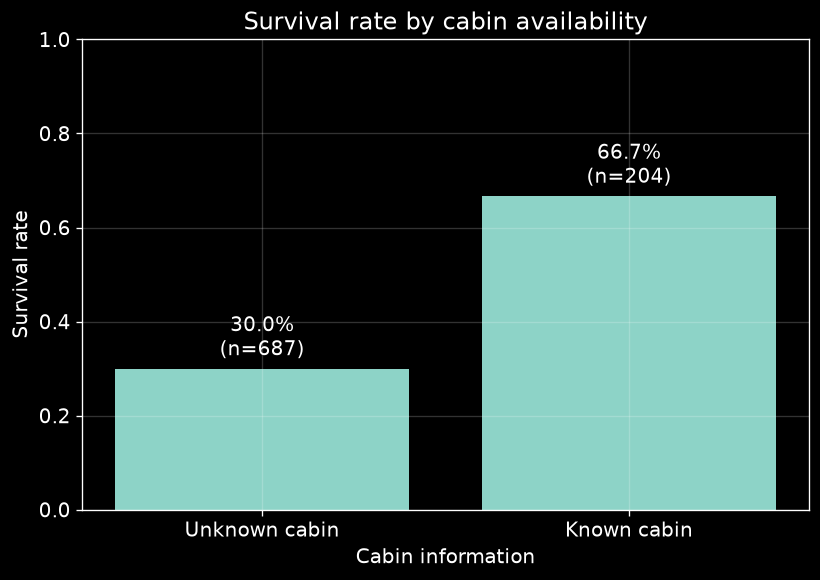

In [37]:

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Unknown cabin", "Known cabin"],
    cabin_stats["survival_rate"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.1%}\n(n={count})"
        for rate, count in zip(
            cabin_stats["survival_rate"],
            cabin_stats["total"]
        )
    ],
    padding=4
)

ax.set_title("Survival rate by cabin availability")
ax.set_xlabel("Cabin information")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [38]:

cabin_class = pd.crosstab(
    cabin_df["Pclass"],
    cabin_df["HasCabin"],
    normalize="index"
)

cabin_class

HasCabin,0,1
Pclass,,
1,0.185185,0.814815
2,0.913043,0.086957
3,0.975560,0.024440


### Cabin Availability — Initial Findings

The `Cabin` feature contains a substantial proportion of missing values (77.1%).

Passengers with known cabin information had a considerably higher observed survival rate (66.7%) than those with missing cabin information (30.0%).

However, cabin availability is strongly associated with passenger class. Approximately 81.5% of first-class passengers had known cabin information, compared with only 8.7% and 2.4% of second- and third-class passengers, respectively.

Therefore, the relationship between cabin availability and survival may be partially explained by passenger class.

Further analysis within individual classes is needed before drawing conclusions about the independent predictive value of cabin availability.


In [39]:

cabin_class_stats = (
    cabin_df.groupby(["Pclass", "HasCabin"])["Survived"]
    .agg(
        total="count",
        survived="sum",
        survival_rate="mean"
    )
)

cabin_class_stats

total  survived  survival_rate
Pclass HasCabin                                
1      0            40        19       0.475000
       1           176       117       0.664773
2      0           168        74       0.440476
       1            16        13       0.812500
3      0           479       113       0.235908
       1            12         6       0.500000

### Cabin Availability — Additional Findings

The association between cabin availability and survival persists within passenger classes.

Among first-class passengers, those with known cabin information had a survival rate of 66.5%, compared with 47.5% among those with missing cabin information.

Similar differences were observed in second and third class. However, only 16 second-class and 12 third-class passengers had known cabin information, making these estimates less reliable.

These findings suggest that cabin availability may contain predictive information beyond passenger class alone. Nevertheless, other factors, such as gender, age, and differences in historical record completeness, may contribute to the observed association.

The `HasCabin` indicator is therefore a candidate for future feature engineering.

In [40]:

cabin_df["Deck"] = (
    cabin_df["Cabin"]
    .str[0]
    .fillna("Unknown")
)

cabin_df["Deck"].value_counts()

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [41]:

deck_stats = (
    cabin_df.groupby("Deck")["Survived"]
    .agg(
        total="count",
        survived="sum",
        survival_rate="mean"
    )
    .sort_index()
)

deck_stats

,total,survived,survival_rate
Deck,,,
A,15,7,0.466667
B,47,35,0.744681
C,59,35,0.593220
D,33,25,0.757576
E,32,24,0.750000
F,13,8,0.615385
G,4,2,0.500000
T,1,0,0.000000
Unknown,687,206,0.299854


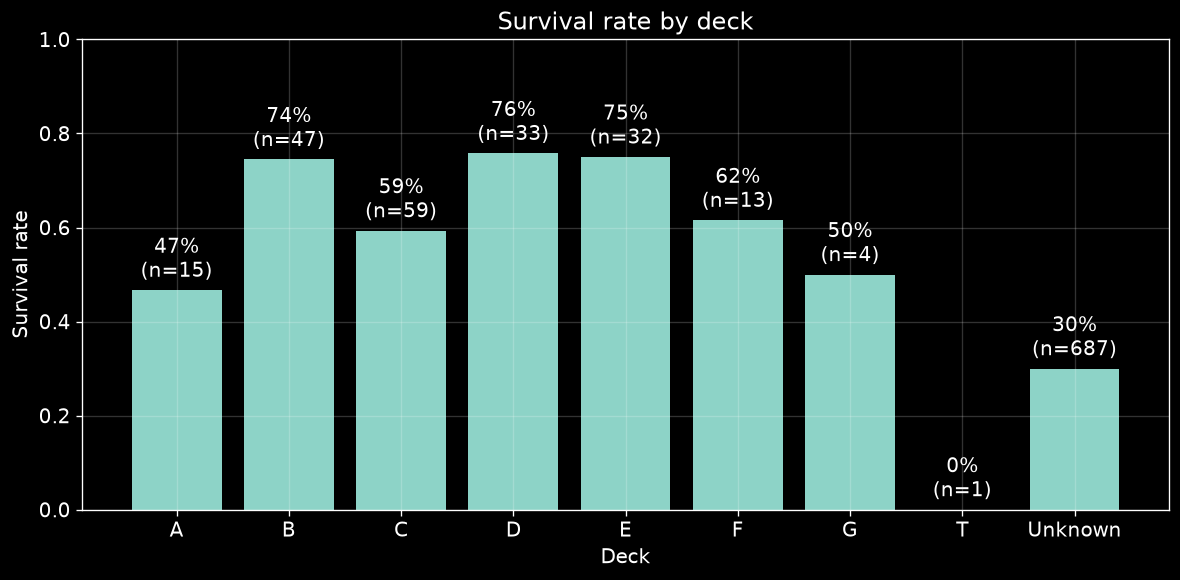

In [42]:

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    deck_stats.index,
    deck_stats["survival_rate"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.0%}\n(n={count})"
        for rate, count in zip(
            deck_stats["survival_rate"],
            deck_stats["total"]
        )
    ],
    padding=4
)

ax.set_title("Survival rate by deck")
ax.set_xlabel("Deck")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

### Deck Analysis — Key Findings

Survival rates vary across decks with known cabin information. Decks B, D, and E show relatively high observed survival rates, while Deck A has a lower rate.

However, most individual deck groups contain relatively few passengers. In particular, decks G and T have only four and one observations, respectively.

Furthermore, cabin information is missing for 77.1% of the training dataset, and cabin availability is strongly associated with passenger class.

These limitations make it difficult to draw reliable conclusions about the independent relationship between deck location and survival.

The potential predictive value of `Deck` and `HasCabin` will be evaluated through cross-validation during feature engineering.

## 9. Ticket Analysis

The `Ticket` feature contains 681 unique values among 891 passengers.

Although ticket identifiers have high cardinality, repeated ticket numbers may indicate passengers traveling together or sharing a booking.

We investigate whether ticket sharing is associated with survival and whether ticket identifiers contain potentially useful information for feature engineering.

In [43]:

train[["Ticket", "Pclass", "Fare", "Survived"]].head(15)

,Ticket,Pclass,Fare,Survived
0,A/5 21171,3,7.2500,0
1,PC 17599,1,71.2833,1
2,STON/O2. 3101282,3,7.9250,1
3,113803,1,53.1000,1
4,373450,3,8.0500,0
5,330877,3,8.4583,0
6,17463,1,51.8625,0
7,349909,3,21.0750,0
8,347742,3,11.1333,1
9,237736,2,30.0708,1


In [44]:

ticket_counts = train["Ticket"].value_counts()

ticket_counts.head(15)

Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
349909          4
347077          4
19950           4
W./C. 6608      4
4133            4
LINE            4
113781          4
Name: count, dtype: int64

In [45]:

ticket_df = train.copy()

ticket_df["TicketGroupSize"] = (
    ticket_df["Ticket"]
    .map(ticket_df["Ticket"].value_counts())
)

ticket_stats = (
    ticket_df.groupby("TicketGroupSize")["Survived"]
    .agg(
        total="count",
        survived="sum",
        survival_rate="mean"
    )
)

ticket_stats

,total,survived,survival_rate
TicketGroupSize,,,
1,547,163,0.297989
2,188,108,0.574468
3,63,44,0.698413
4,44,22,0.500000
5,10,0,0.000000
6,18,0,0.000000
7,21,5,0.238095


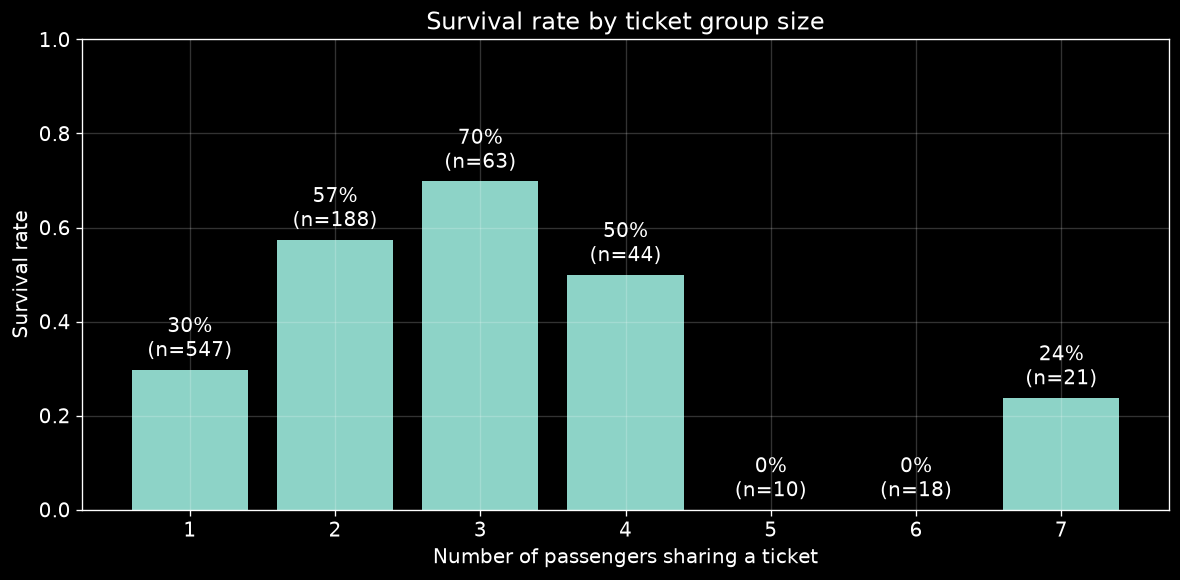

In [46]:

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    ticket_stats.index.astype(str),
    ticket_stats["survival_rate"]
)

ax.bar_label(
    bars,
    labels=[
        f"{rate:.0%}\n(n={count})"
        for rate, count in zip(
            ticket_stats["survival_rate"],
            ticket_stats["total"]
        )
    ],
    padding=4
)

ax.set_title("Survival rate by ticket group size")
ax.set_xlabel("Number of passengers sharing a ticket")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [47]:

ticket_df["FamilySize"] = (
    ticket_df["SibSp"]
    + ticket_df["Parch"]
    + 1
)

pd.crosstab(
    ticket_df["FamilySize"],
    ticket_df["TicketGroupSize"]
)

TicketGroupSize,1,2,3,4,5,6,7
FamilySize,,,,,,,
1,462,40,17,9,2,0,7
2,58,87,15,1,0,0,0
3,24,48,24,3,3,0,0
4,1,11,6,11,0,0,0
5,1,2,0,12,0,0,0
6,0,0,1,4,5,12,0
7,1,0,0,4,0,0,7
8,0,0,0,0,0,6,0
11,0,0,0,0,0,0,7


### Ticket Analysis — Key Findings

The `Ticket` feature contains 681 unique values among 891 passengers, indicating that some passengers share ticket identifiers.

Passengers with unique tickets had an observed survival rate of approximately 30%. Those sharing tickets with one or two other passengers had higher survival rates, ranging from 57% to 70%.

Survival rates generally decreased for larger ticket groups, although some categories contain very few distinct tickets.

This non-linear pattern resembles the relationship observed for `FamilySize`, suggesting that ticket sharing may partially reflect family or travel-group structure.

However, passengers sharing a ticket are not necessarily relatives, and ticket group sizes calculated from the training dataset may be incomplete.

`TicketGroupSize` is a potential feature engineering candidate. Its additional predictive value beyond `FamilySize` should be evaluated through cross-validation.
